In [17]:
import numpy as np, pandas as pd, tensorflow as tf, os
IMG, BS = 224, 32
df = pd.read_csv('/kaggle/working/splits.csv')
classes = sorted(df.label.unique()); cidx = {c: i for i, c in enumerate(classes)}
print(len(df), classes)
print(sorted(os.listdir('/kaggle/working')))

6812 ['cocci', 'healthy', 'ncd', 'salmo']
['.virtual_documents', 'baseline_group.keras', 'baseline_random.keras', 'confusion_matrix.png', 'image_metadata.csv', 'improved_group.keras', 'probs_group.npy', 'probs_improved_test.npy', 'probs_improved_val.npy', 'probs_random.npy', 'splits.csv', 'test_group.csv', 'test_random.csv']


In [19]:
# ===== A.iv + A.v | Split table and leakage check =====
GROUP_COL = 'group'   # <-- change to the column that says which bird/farm/batch a photo is from

for col in ['split_group', 'split_random']:
    print(f"\n--- {col}: images per class ---")
    t = pd.crosstab(df.label, df[col])[['train', 'val', 'test']]
    t.loc['TOTAL'] = t.sum()
    print(t)

def leaked(col, key):
    """How many values of `key` appear in more than one split."""
    return int((df.groupby(key)[col].nunique() > 1).sum())

rows = []
for col in ['split_group', 'split_random']:
    r = {'split': col, 'duplicate files across splits': leaked(col, 'md5')}
    if GROUP_COL in df.columns:
        r[f'{GROUP_COL}s across splits'] = leaked(col, GROUP_COL)
    rows.append(r)
leak = pd.DataFrame(rows)
print("\n=== LEAKAGE CHECK (0 is what we want) ===")
print(leak.to_string(index=False))
leak.to_csv(OUT + 'leakage_check.csv', index=False)


--- split_group: images per class ---
split_group  train  val  test
label                        
cocci         1500  304   299
healthy       1467  295   295
ncd            269   54    53
salmo         1632  320   324
TOTAL         4868  973   971

--- split_random: images per class ---
split_random  train   val  test
label                          
cocci          1472   315   316
healthy        1440   309   308
ncd             263    56    57
salmo          1593   342   341
TOTAL          4768  1022  1022

=== LEAKAGE CHECK (0 is what we want) ===
       split  duplicate files across splits  groups across splits
 split_group                              0                     0
split_random                            137                   137


In [6]:
import os, sys, random, platform
import numpy as np, tensorflow as tf

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Platform   :", platform.platform())
print("GPUs       :", tf.config.list_physical_devices('GPU'))

Python     : 3.13.16
TensorFlow : 2.21.0
NumPy      : 2.1.3
Platform   : Linux-6.18.55+-x86_64-with-glibc2.39
GPUs       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [20]:
# ===== B.iv + B.v | Hardware, software and settings =====
import platform, sys, subprocess, sklearn, tensorflow as tf

print("Python:", sys.version.split()[0], "| TensorFlow:", tf.__version__,
      "| scikit-learn:", sklearn.__version__, "| NumPy:", np.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))
try:
    print(subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout)
except Exception:
    pass
print("Platform:", platform.platform())

SETTINGS = {
    'seed': 42, 'image_size': 224, 'batch_size': 32,
    'baseline': 'MobileNetV2 (ImageNet weights), dropout 0.3',
    'phase 1': 'frozen base, Adam 1e-3, 8 epochs',
    'phase 2': 'last 40 layers unfrozen, Adam 1e-5, up to 8 epochs, early stopping patience 3',
    'augmentation': 'horizontal flip, rotation 0.1',
}
for k, v in SETTINGS.items():
    print(f"{k:>14}: {v}")

Python: 3.13.16 | TensorFlow: 2.21.0 | scikit-learn: 1.6.1 | NumPy: 2.1.3
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-a5432ba3-a427-9f2b-0cb0-6eb68a7ce394)
GPU 1: Tesla T4 (UUID: GPU-e4ae1145-785e-3e08-0aac-66c0b7246fce)

Platform: Linux-6.18.55+-x86_64-with-glibc2.39
          seed: 42
    image_size: 224
    batch_size: 32
      baseline: MobileNetV2 (ImageNet weights), dropout 0.3
       phase 1: frozen base, Adam 1e-3, 8 epochs
       phase 2: last 40 layers unfrozen, Adam 1e-5, up to 8 epochs, early stopping patience 3
  augmentation: horizontal flip, rotation 0.1


In [7]:
!pip install imagehash -q

In [8]:
import os
print("Contents of /kaggle/input:", os.listdir('/kaggle/input'))

n = 0
for dirpath, dirs, files in os.walk('/kaggle/input'):
    n += len(files)
    if n <= 15:
        print(dirpath, '| subfolders:', dirs[:5], '| files:', files[:3])
print("Total files of any type:", n)

Contents of /kaggle/input: ['datasets']
/kaggle/input | subfolders: ['datasets'] | files: []
/kaggle/input/datasets | subfolders: ['kausthubkannan'] | files: []
/kaggle/input/datasets/kausthubkannan | subfolders: ['poultry-diseases-detection'] | files: []
/kaggle/input/datasets/kausthubkannan/poultry-diseases-detection | subfolders: ['poultry_diseases'] | files: []
/kaggle/input/datasets/kausthubkannan/poultry-diseases-detection/poultry_diseases | subfolders: ['cocci', 'healthy', 'ncd', 'salmo'] | files: []
Total files of any type: 6812


In [9]:
import os
print(os.listdir('/kaggle/input'))
n = sum(len(f) for _, _, f in os.walk('/kaggle/input'))
print("Total files:", n)

['datasets']
Total files: 6812


In [10]:
from pathlib import Path
import pandas as pd

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
paths = [p for p in Path('/kaggle/input/datasets').rglob('*') if p.suffix.lower() in IMG_EXT]
print("Total image files:", len(paths))

df = pd.DataFrame({'path': paths})
df['label'] = df.path.apply(lambda p: p.parent.name)
print(df.label.value_counts())
print("\nExample paths:")
for p in df.path.sample(5, random_state=42): print(p)

Total image files: 6812
label
salmo      2276
cocci      2103
healthy    2057
ncd         376
Name: count, dtype: int64

Example paths:
/kaggle/input/datasets/kausthubkannan/poultry-diseases-detection/poultry_diseases/healthy/healthy.954.jpg
/kaggle/input/datasets/kausthubkannan/poultry-diseases-detection/poultry_diseases/healthy/healthy.1752.jpg
/kaggle/input/datasets/kausthubkannan/poultry-diseases-detection/poultry_diseases/cocci/cocci.339.jpg
/kaggle/input/datasets/kausthubkannan/poultry-diseases-detection/poultry_diseases/healthy/healthy.127.jpg
/kaggle/input/datasets/kausthubkannan/poultry-diseases-detection/poultry_diseases/salmo/salmo.726.jpg


In [11]:
# ===== SECTION A.i-A.iii | Dataset listing + preprocessing and data-quality checks =====
# Rubric: Dataset selection (10), Dataset preparation and integrity (10)
# Self-contained: rebuilds df from scratch, so it is safe to re-run at any time
import hashlib, time, numpy as np, pandas as pd, imagehash
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
files = sorted(str(p) for p in Path('/kaggle/input/datasets').rglob('*')
               if p.suffix.lower() in IMG_EXT)
print("Total image files:", len(files))

def process(p):
    try:
        raw = open(p, 'rb').read()
        md5 = hashlib.md5(raw).hexdigest()
        with Image.open(p) as im:
            im.load()
            w, h, mode, fmt = im.width, im.height, im.mode, im.format
            ph = imagehash.phash(im.convert('RGB')).hash.flatten().astype(np.uint8)
        return dict(path=p, label=Path(p).parent.name, w=w, h=h, mode=mode,
                    fmt=fmt, md5=md5, ok=True, ph=ph)
    except Exception:
        return dict(path=p, label=Path(p).parent.name, ok=False, ph=None)

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    rows = list(ex.map(process, files))
print(f"Read all images in {time.time()-t0:.0f}s")

all_df = pd.DataFrame(rows)
print("Class counts (all files):\n", all_df.label.value_counts())
print("Corrupt/unreadable:", (~all_df.ok).sum())

df = all_df[all_df.ok].reset_index(drop=True)
H = np.stack(df.ph.values).astype(np.float32)
df = df.drop(columns=['ph', 'ok'])

print("\nFormats:\n", df.fmt.value_counts())
print("Modes:\n", df['mode'].value_counts())
print("Width  min/median/max:", df.w.min(), df.w.median(), df.w.max())
print("Height min/median/max:", df.h.min(), df.h.median(), df.h.max())
print("Exact duplicates (same MD5):", df.md5.duplicated().sum())
dup = df[df.md5.duplicated(keep=False)]
print("Exact-duplicate sets crossing classes:",
      (dup.groupby('md5').label.nunique() > 1).sum())

# Near-duplicate groups (pHash Hamming distance <= 6)
ham = 64 - (H @ H.T + (1 - H) @ (1 - H).T)
n_groups, df['group'] = connected_components(csr_matrix(ham <= 6))
sizes = df.group.value_counts()
print("\nImages:", len(df), "| groups:", n_groups)
print("Groups with >1 image:", (sizes > 1).sum(), "| largest group:", sizes.max())
print("Images inside multi-image groups:", sizes[sizes > 1].sum())
print("Groups containing more than one class:",
      (df.groupby('group').label.nunique() > 1).sum())

df.to_csv('/kaggle/working/image_metadata.csv', index=False)
print("\nSaved /kaggle/working/image_metadata.csv")

Total image files: 6812
Read all images in 231s
Class counts (all files):
 label
salmo      2276
cocci      2103
healthy    2057
ncd         376
Name: count, dtype: int64
Corrupt/unreadable: 0

Formats:
 fmt
JPEG    6812
Name: count, dtype: int64
Modes:
 mode
RGB    6812
Name: count, dtype: int64
Width  min/median/max: 1152 2048.0 4160
Height min/median/max: 1152 1440.0 4160
Exact duplicates (same MD5): 318
Exact-duplicate sets crossing classes: 0

Images: 6812 | groups: 6494
Groups with >1 image: 260 | largest group: 4
Images inside multi-image groups: 578
Groups containing more than one class: 0

Saved /kaggle/working/image_metadata.csv


In [12]:
# ===== SECTION A.iv + A.v | Train/val/test splits and leakage prevention =====
# Rubric: Dataset preparation and integrity (10)
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

sizes = df.group.value_counts()
print("Largest group:", sizes.max(), "images (", round(100*sizes.max()/len(df),1), "% of data )")

# Group-aware split (~70/15/15)
df['split_group'] = 'train'
sg1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trval_idx, test_idx = next(sg1.split(df, df.label, df.group))
df.loc[df.index[test_idx], 'split_group'] = 'test'
trval = df.iloc[trval_idx]
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
_, val_rel = next(sg2.split(trval, trval.label, trval.group))
df.loc[trval.index[val_rel], 'split_group'] = 'val'

# Random image-level split (same proportions)
idx = np.arange(len(df))
tr_i, tmp_i = train_test_split(idx, test_size=0.30, stratify=df.label, random_state=42)
va_i, te_i = train_test_split(tmp_i, test_size=0.50, stratify=df.label.iloc[tmp_i], random_state=42)
df['split_random'] = 'train'
df.loc[df.index[va_i], 'split_random'] = 'val'
df.loc[df.index[te_i], 'split_random'] = 'test'

# Leakage assertions
g = df.groupby('group').split_group.nunique()
assert (g == 1).all(), "LEAK: a near-duplicate group appears in several splits"
for a, b in [('train','test'), ('train','val'), ('val','test')]:
    s1 = set(df[df.split_group==a].md5); s2 = set(df[df.split_group==b].md5)
    assert not (s1 & s2), f"LEAK: identical files in {a} and {b}"
print("Group-aware split passed: no group or exact duplicate crosses splits\n")

grp_split = df.groupby('group').split_random.nunique()
print("Near-duplicate groups spread across splits in RANDOM split:", (grp_split > 1).sum())
tr_groups = set(df[df.split_random=='train'].group)
te_rand = df[df.split_random=='test']
print("Random-split test images with a near-duplicate in train:",
      te_rand.group.isin(tr_groups).sum(), "of", len(te_rand))

print("\nGroup-aware class counts:\n", pd.crosstab(df.label, df.split_group))
print("\nRandom class counts:\n", pd.crosstab(df.label, df.split_random))
df.to_csv('/kaggle/working/splits.csv', index=False)

Largest group: 4 images ( 0.1 % of data )
Group-aware split passed: no group or exact duplicate crosses splits

Near-duplicate groups spread across splits in RANDOM split: 137
Random-split test images with a near-duplicate in train: 61 of 1022

Group-aware class counts:
 split_group  test  train  val
label                        
cocci         299   1500  304
healthy       295   1467  295
ncd            53    269   54
salmo         324   1632  320

Random class counts:
 split_random  test  train  val
label                         
cocci          316   1472  315
healthy        308   1440  309
ncd             57    263   56
salmo          341   1593  342


Total images: 6812
         images  percent
label                   
salmo      2276     33.4
cocci      2103     30.9
healthy    2057     30.2
ncd         376      5.5


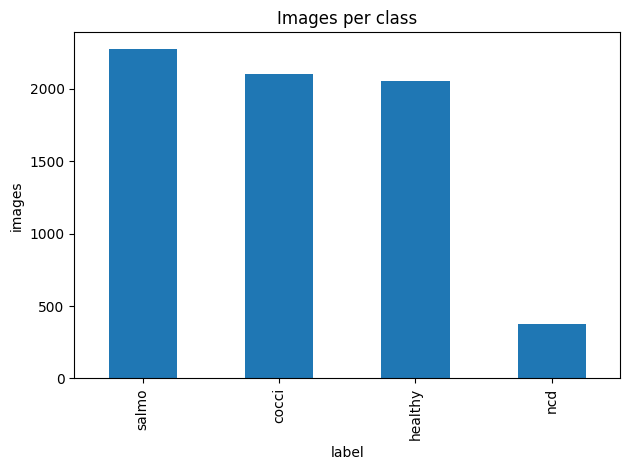


Unreadable/corrupt files: 0
Exact duplicate files: 318
Same picture with different labels: 0

Image size (pixels):
           w       h
min   1152.0  1152.0
mean  2083.0  2153.0
max   4160.0  4160.0


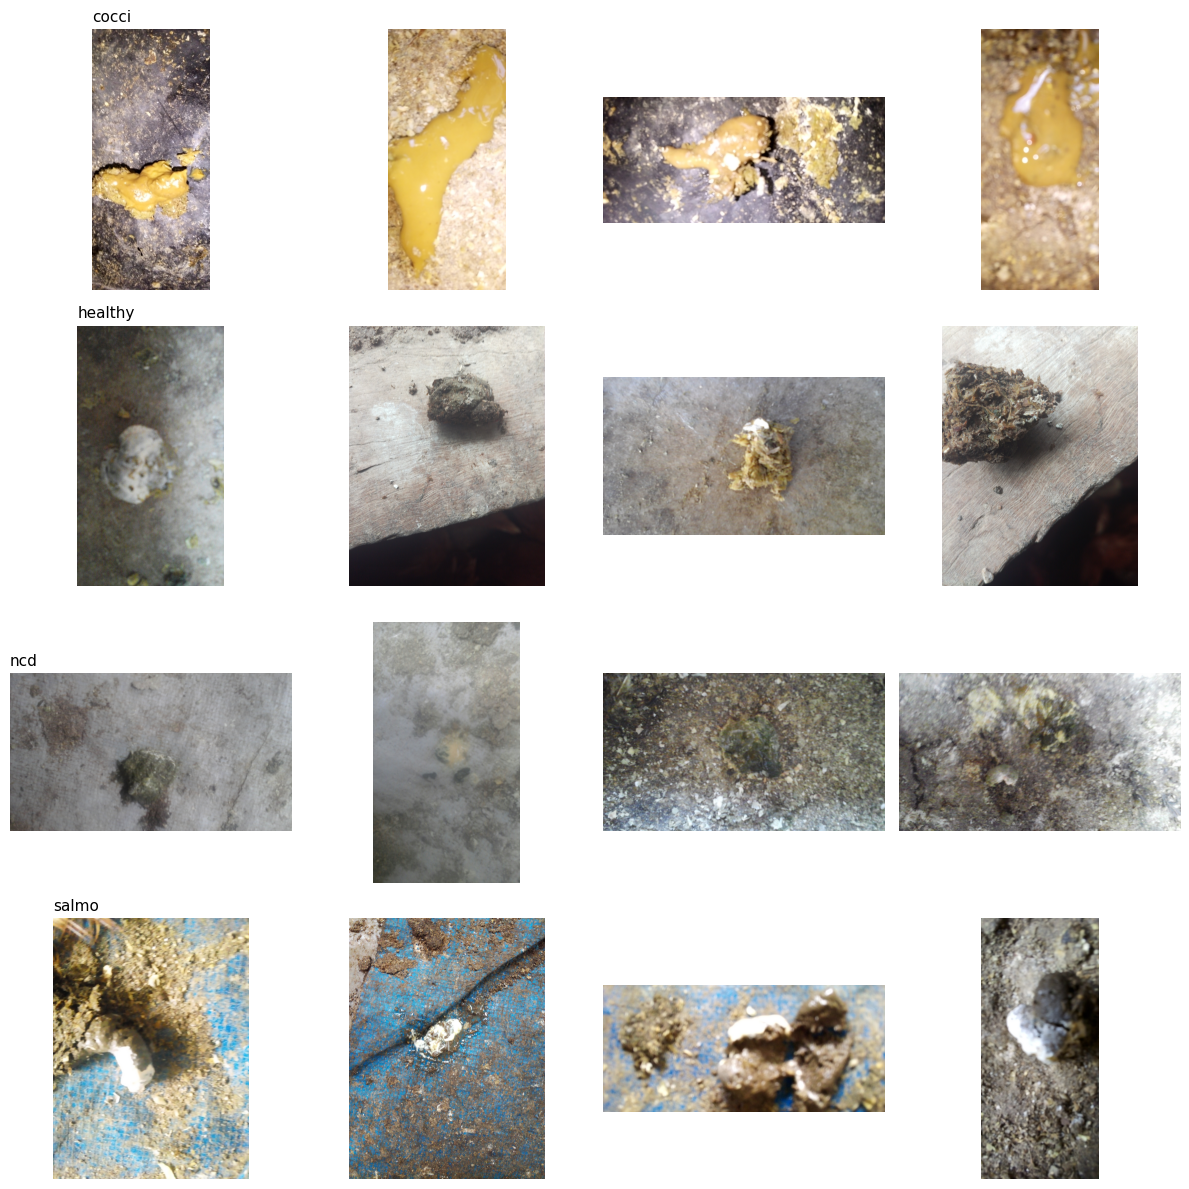


Preprocessing: resize to 224x224, MobileNetV2 scaling to [-1, 1]. Augmentation on training images only.


In [18]:
# ===== A.ii + A.iii | Dataset description and data-quality checks =====
import numpy as np, pandas as pd, hashlib, matplotlib.pyplot as plt
from PIL import Image

OUT = '/kaggle/working/'
print("Total images:", len(df))
cnt = df.label.value_counts()
print(pd.DataFrame({'images': cnt, 'percent': (cnt / len(df) * 100).round(1)}))
cnt.plot(kind='bar', title='Images per class')
plt.ylabel('images'); plt.tight_layout()
plt.savefig(OUT + 'fig_class_balance.png', dpi=150); plt.show()

# Quality checks: unreadable files, image sizes, exact duplicates
bad, sizes, hashes = [], [], []
for p in df.path:
    try:
        with Image.open(p) as im:
            sizes.append(im.size)
            im.verify()
    except Exception:
        bad.append(p); sizes.append((0, 0))
    with open(p, 'rb') as f:
        hashes.append(hashlib.md5(f.read()).hexdigest())
df['md5'] = hashes
df['w'], df['h'] = zip(*sizes)

print("\nUnreadable/corrupt files:", len(bad))
print("Exact duplicate files:", int(df.md5.duplicated().sum()))
conflict = df.groupby('md5').label.nunique()
print("Same picture with different labels:", int((conflict > 1).sum()))
print("\nImage size (pixels):")
print(df[['w', 'h']].describe().loc[['min', 'mean', 'max']].round(0))

# Sample pictures: 4 per class
fig, axs = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes)))
for r, c in enumerate(classes):
    for k, i in enumerate(df[df.label == c].sample(4, random_state=1).index):
        axs[r, k].imshow(Image.open(df.path[i]).convert('RGB')); axs[r, k].axis('off')
        if k == 0: axs[r, k].set_title(c, loc='left', fontsize=11)
plt.tight_layout(); plt.savefig(OUT + 'fig_dataset_samples.png', dpi=130); plt.show()

# Preprocessing used (write this in the report)
print("\nPreprocessing: resize to 224x224, MobileNetV2 scaling to [-1, 1]. "
      "Augmentation on training images only.")

In [13]:
# ===== SECTION B.ii + C.i to C.iii | Baseline implementation and first results =====
# Rubric: Baseline implementation (20), Results (15)
# Baseline = MobileNetV2, ImageNet transfer learning, deliberately plain
import tensorflow as tf, time
from sklearn.metrics import classification_report

IMG, BS = 224, 32
classes = sorted(df.label.unique()); cidx = {c:i for i,c in enumerate(classes)}
print("Classes:", classes)

aug = tf.keras.Sequential([tf.keras.layers.RandomFlip('horizontal'),
                           tf.keras.layers.RandomRotation(0.1)])

def make_ds(d, train):
    def load(p, l):
        x = tf.image.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        x.set_shape([None, None, 3])
        x = tf.image.resize(x, (IMG, IMG))
        return tf.keras.applications.mobilenet_v2.preprocess_input(x), l
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.map(cidx).values.astype('int32')))
    if train: ds = ds.shuffle(2000, seed=42)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BS)
    if train: ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

def run_experiment(split_col, name):
    tf.keras.utils.set_random_seed(42)
    tr, va, te = [df[df[split_col]==s] for s in ('train','val','test')]
    base = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet',
                                             input_shape=(IMG,IMG,3), pooling='avg')
    base.trainable = False
    model = tf.keras.Sequential([base, tf.keras.layers.Dropout(0.3),
                                 tf.keras.layers.Dense(len(classes), activation='softmax')])
    t0 = time.time()
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h1 = model.fit(make_ds(tr,True), validation_data=make_ds(va,False), epochs=8, verbose=2)

    base.trainable = True
    for layer in base.layers[:-40]: layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h2 = model.fit(make_ds(tr,True), validation_data=make_ds(va,False), epochs=8, verbose=2,
                   callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    print(f"[{name}] training time: {(time.time()-t0)/60:.1f} min")

    model.save(f'/kaggle/working/baseline_{name}.keras')
    probs = model.predict(make_ds(te,False), verbose=0)
    np.save(f'/kaggle/working/probs_{name}.npy', probs)
    te[['path','label']].to_csv(f'/kaggle/working/test_{name}.csv', index=False)
    y_true = te.label.map(cidx).values
    print(f"\n=== {name} split: TEST RESULTS ===")
    print(classification_report(y_true, probs.argmax(1), target_names=classes, digits=3))
    return model, h1, h2, probs, y_true

res_group  = run_experiment('split_group',  'group')
res_random = run_experiment('split_random', 'random')

Classes: ['cocci', 'healthy', 'ncd', 'salmo']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
153/153 - 98s - 640ms/step - accuracy: 0.8303 - loss: 0.5407 - val_accuracy: 0.9250 - val_loss: 0.2241
Epoch 2/8
153/153 - 74s - 484ms/step - accuracy: 0.9152 - loss: 0.2443 - val_accuracy: 0.9548 - val_loss: 0.1512
Epoch 3/8
153/153 - 74s - 482ms/step - accuracy: 0.9357 - loss: 0.1780 - val_accuracy: 0.9538 - val_loss: 0.1457
Epoch 4/8
153/153 - 74s - 484ms/step - accuracy: 0.9458 - loss: 0.1610 - val_accuracy: 0.9476 - val_loss: 0.1386
Epoch 5/8
153/153 - 73s - 480ms/step - accuracy: 0.9412 - loss: 0.1603 - val_accuracy: 0.9589 - val_loss: 0.1241
Epoch 6/8
153/153 - 73s - 479ms/step - accuracy: 0.9470 - loss: 0.1501 - val_accuracy: 0.9568 - val_loss: 0.1203
Epoch 7/8
153/153 - 73s - 478ms/step - accuracy: 0.9540 - loss: 0.1433 - val_accuracy: 0.9568 - val_loss: 0.1220
Epoch 8/8
153/153 - 73s - 476ms/step - accuracy: 0.9544 - loss: 0.1360 - val_accuracy: 0.9651 - val_loss: 0.1074
E

E0000 00:00:1793975400.772659     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


153/153 - 105s - 686ms/step - accuracy: 0.8217 - loss: 0.5219 - val_accuracy: 0.9466 - val_loss: 0.1832
Epoch 2/8
153/153 - 70s - 456ms/step - accuracy: 0.8389 - loss: 0.4507 - val_accuracy: 0.9383 - val_loss: 0.2124
Epoch 3/8
153/153 - 69s - 453ms/step - accuracy: 0.8548 - loss: 0.3970 - val_accuracy: 0.9353 - val_loss: 0.2149
Epoch 4/8
153/153 - 70s - 455ms/step - accuracy: 0.8687 - loss: 0.3548 - val_accuracy: 0.9373 - val_loss: 0.1964
[group] training time: 15.5 min

=== group split: TEST RESULTS ===
              precision    recall  f1-score   support

       cocci      0.983     0.987     0.985       299
     healthy      0.834     0.990     0.905       295
         ncd      0.902     0.698     0.787        53
       salmo      0.982     0.849     0.911       324

    accuracy                          0.926       971
   macro avg      0.926     0.881     0.897       971
weighted avg      0.933     0.926     0.925       971

Epoch 1/8
149/149 - 83s - 559ms/step - accuracy: 0.8322

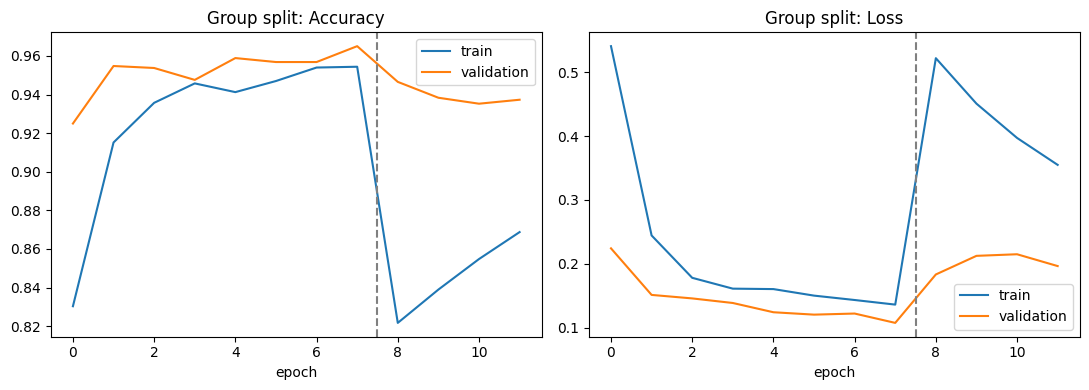

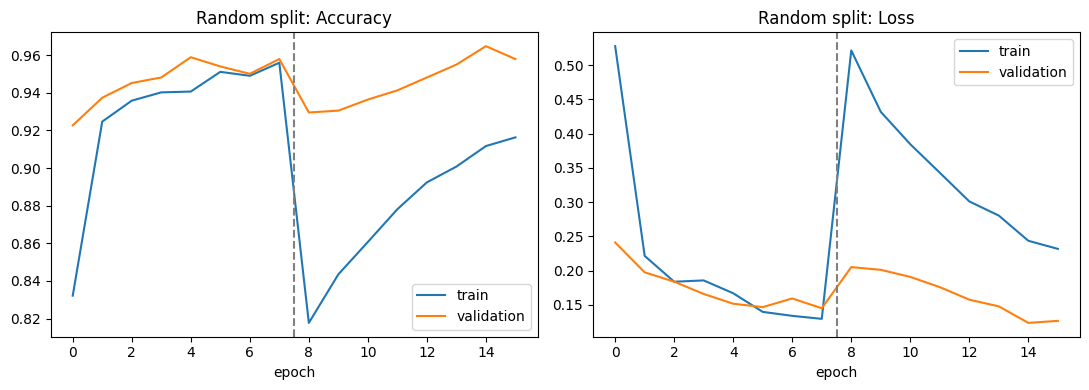

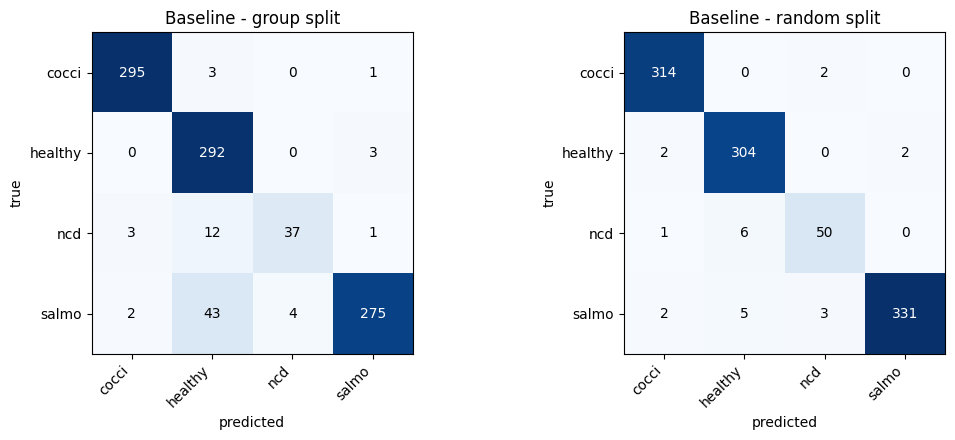

                                                0                        1
model                      baseline (group split)  baseline (random split)
accuracy                                    0.926                    0.977
macro_F1                                    0.897                     0.96
sick_caught_%                               91.42                   98.459
healthy_wrongly_flagged_%                   1.017                    1.299
recall_cocci                                0.987                    0.994
recall_healthy                               0.99                    0.987
recall_ncd                                  0.698                    0.877
recall_salmo                                0.849                    0.971


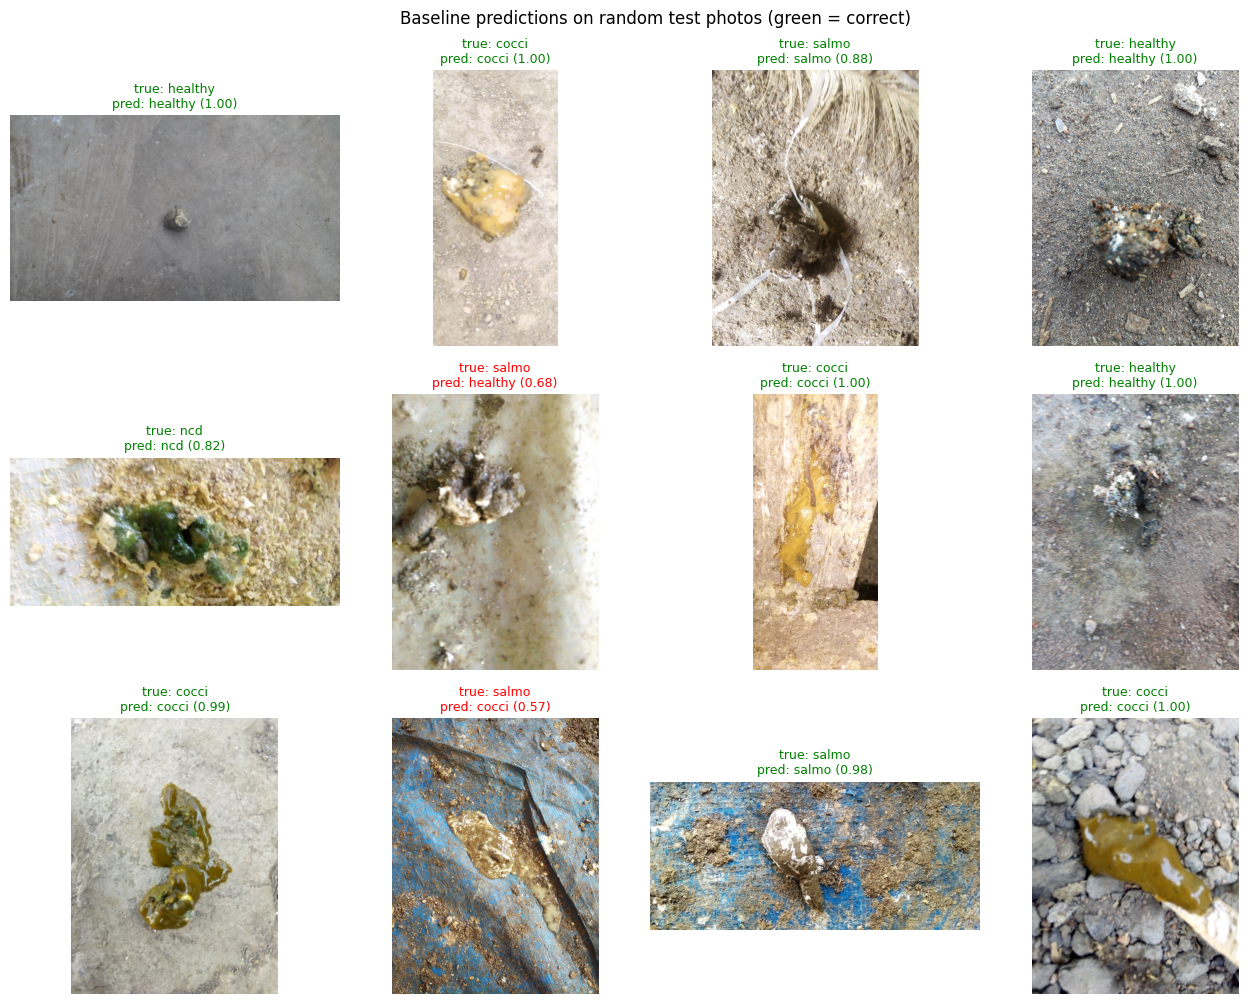


Baseline mistakes on test set: 72 of 971


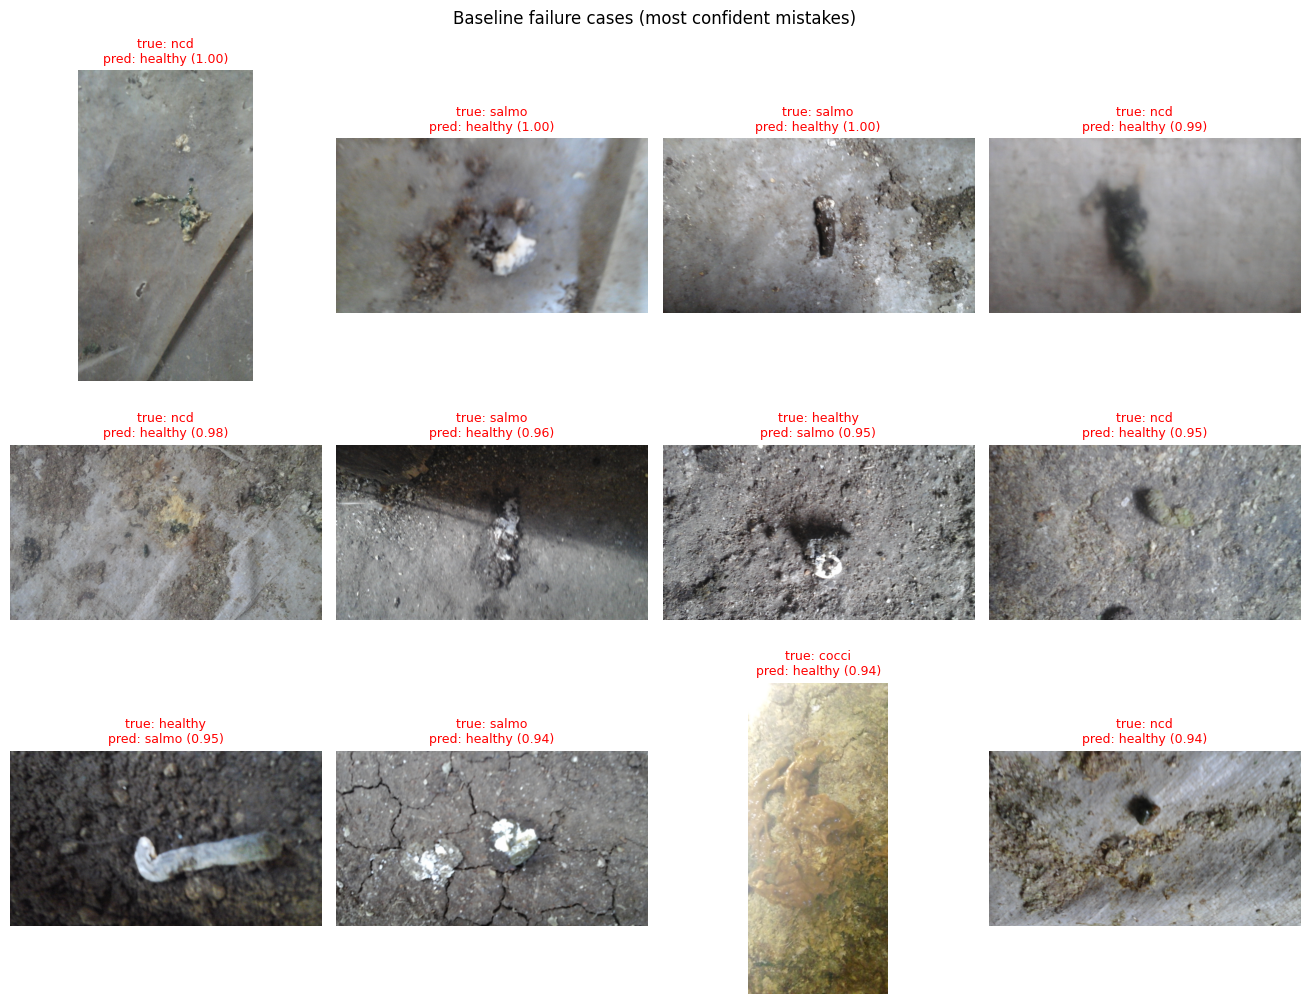


Most common mix-ups (count, true -> predicted):
   43  salmo -> healthy
   12  ncd -> healthy
    4  salmo -> ncd
    3  ncd -> cocci
    3  healthy -> salmo
Average confidence when wrong: 0.74 | when right: 0.97


In [21]:
# ===== C.iii + C.iv + D.i + D.ii | Baseline results and failure cases =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

OUT = '/kaggle/working/'
model_g, h1, h2, probs_g, y_g = res_group
model_r, h1r, h2r, probs_r, y_r = res_random
te_g = df[df.split_group == 'test'].reset_index(drop=True)
pred_g, conf_g = probs_g.argmax(1), probs_g.max(1)
K = len(classes)

# 1. Training curves
def curves(a, b, title, fn):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for k, (m, name) in enumerate([('accuracy', 'Accuracy'), ('loss', 'Loss')]):
        ax[k].plot(a.history[m] + b.history[m], label='train')
        ax[k].plot(a.history['val_' + m] + b.history['val_' + m], label='validation')
        ax[k].axvline(len(a.history[m]) - 0.5, ls='--', c='gray')
        ax[k].set_title(f'{title}: {name}'); ax[k].set_xlabel('epoch'); ax[k].legend()
    plt.tight_layout(); plt.savefig(OUT + fn, dpi=150); plt.show()
curves(h1, h2, 'Group split', 'fig_curves_group.png')
curves(h1r, h2r, 'Random split', 'fig_curves_random.png')

# 2. Confusion matrices (draw_cm is reused in the comparison cell)
def draw_cm(ax, y, pred, title):
    cm = confusion_matrix(y, pred, labels=range(K))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(K)); ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.set_yticks(range(K)); ax.set_yticklabels(classes)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_title(title); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    return cm

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
cm_g = draw_cm(ax[0], y_g, pred_g, 'Baseline - group split')
draw_cm(ax[1], y_r, probs_r.argmax(1), 'Baseline - random split')
plt.tight_layout(); plt.savefig(OUT + 'fig_confusion_baseline.png', dpi=150); plt.show()

# 3. Results table
def summarize(name, probs, y):
    pred = probs.argmax(1); h = cidx['healthy']
    sick = y != h; flag = pred != h
    r = {'model': name, 'accuracy': accuracy_score(y, pred),
         'macro_F1': f1_score(y, pred, average='macro'),
         'sick_caught_%': 100 * (sick & flag).sum() / sick.sum(),
         'healthy_wrongly_flagged_%': 100 * (~sick & flag).sum() / (~sick).sum()}
    for c in classes:
        i = cidx[c]; r['recall_' + c] = ((pred == i) & (y == i)).sum() / (y == i).sum()
    return r
tab = pd.DataFrame([summarize('baseline (group split)', probs_g, y_g),
                    summarize('baseline (random split)', probs_r, y_r)]).round(3)
print(tab.T)
tab.to_csv(OUT + 'baseline_results.csv', index=False)

# 4. Sample outputs: 12 random test photos with predictions
def show_grid(idx, title, fn):
    cols = 4; rows = int(np.ceil(len(idx) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(3.3 * cols, 3.4 * rows))
    axs = np.array(axs).ravel()
    for a in axs: a.axis('off')
    for a, i in zip(axs, idx):
        a.imshow(Image.open(te_g.path[i]).convert('RGB'))
        ok = pred_g[i] == y_g[i]
        a.set_title(f"true: {classes[y_g[i]]}\npred: {classes[pred_g[i]]} ({conf_g[i]:.2f})",
                    color='green' if ok else 'red', fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(OUT + fn, dpi=130); plt.show()

rng = np.random.default_rng(42)
show_grid(rng.choice(len(te_g), 12, replace=False),
          'Baseline predictions on random test photos (green = correct)', 'fig_samples_baseline.png')

# 5. Failure cases: the most confident mistakes
wrong = np.where(pred_g != y_g)[0]
print(f"\nBaseline mistakes on test set: {len(wrong)} of {len(y_g)}")
worst = wrong[np.argsort(-conf_g[wrong])][:12]
show_grid(worst, 'Baseline failure cases (most confident mistakes)', 'fig_failures_baseline.png')

pairs = [(cm_g[i, j], classes[i], classes[j]) for i in range(K) for j in range(K) if i != j and cm_g[i, j] > 0]
print("\nMost common mix-ups (count, true -> predicted):")
for n_, a, b in sorted(pairs, reverse=True)[:5]:
    print(f"  {n_:>3}  {a} -> {b}")
print(f"Average confidence when wrong: {conf_g[wrong].mean():.2f} | when right: {conf_g[pred_g == y_g].mean():.2f}")

In [14]:
# ===== RESTORE | Reload data and settings after a restart =====
import numpy as np, pandas as pd, tensorflow as tf, random

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

df = pd.read_csv('/kaggle/working/splits.csv')
IMG, BS = 224, 32
classes = sorted(df.label.unique())
cidx = {c: i for i, c in enumerate(classes)}

print("Pictures:", len(df))
print("Classes:", classes)
print(pd.crosstab(df.label, df.split_group))
print("GPU:", tf.config.list_physical_devices('GPU'))

Pictures: 6812
Classes: ['cocci', 'healthy', 'ncd', 'salmo']
split_group  test  train  val
label                        
cocci         299   1500  304
healthy       295   1467  295
ncd            53    269   54
salmo         324   1632  320
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [15]:
# ===== SECTION D.iv | Improved model: NCD fix + triage (Deliverable 4 preview) =====
# All choices (NCD boost, refer-to-vet line) are made on VALIDATION data.
# The TEST set is used once, at the very end.
import numpy as np, pandas as pd, tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score

IMG, BS = 224, 32
classes = sorted(df.label.unique()); cidx = {c: i for i, c in enumerate(classes)}
tf.keras.utils.set_random_seed(42)

tr = df[df.split_group == 'train']
va = df[df.split_group == 'val']
te = df[df.split_group == 'test']

# 1. Show NCD pictures 3 times in training
tr_big = pd.concat([tr] + [tr[tr.label == 'ncd']] * 2).sample(frac=1, random_state=42)
print("Training pictures:", len(tr), "->", len(tr_big))
print(tr_big.label.value_counts())

# 2. Stronger photo changes (plain TensorFlow functions, picture only)
def augment(x):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.random_flip_up_down(x)
    x = tf.image.random_brightness(x, max_delta=40)
    x = tf.image.random_contrast(x, 0.75, 1.25)
    x = tf.image.random_saturation(x, 0.8, 1.2)
    scale = tf.random.uniform([], 0.85, 1.0)
    size = tf.cast(tf.cast(IMG, tf.float32) * scale, tf.int32)
    x = tf.image.random_crop(x, [size, size, 3])
    x = tf.image.resize(x, (IMG, IMG))
    return tf.clip_by_value(x, 0.0, 255.0)

def make_ds2(d, train, flip=False):
    labels = d.label.map(cidx).values.astype('int32')
    paths = d.path.values
    def load(p, l):
        x = tf.image.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        x.set_shape([None, None, 3])
        x = tf.image.resize(x, (IMG, IMG))
        if train:
            x = augment(x)
        if flip:
            x = tf.image.flip_left_right(x)
        x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
        return x, l
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if train:
        ds = ds.shuffle(3000, seed=42)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BS)
    return ds.prefetch(tf.data.AUTOTUNE)

# 3. Model: same MobileNetV2, trained in two stages
base = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet',
                                         input_shape=(IMG, IMG, 3), pooling='avg')
base.trainable = False
model2 = tf.keras.Sequential([base, tf.keras.layers.Dropout(0.4),
                              tf.keras.layers.Dense(len(classes), activation='softmax')])
stop = lambda p: tf.keras.callbacks.EarlyStopping(patience=p, restore_best_weights=True)
slow = tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, min_lr=1e-7)

# Stage 1: train only the new top layer
model2.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model2.fit(make_ds2(tr_big, True), validation_data=make_ds2(va, False),
           epochs=12, callbacks=[stop(3)], verbose=2)

# Stage 2: fine-tune the last 80 layers
base.trainable = True
for layer in base.layers[:-80]:
    layer.trainable = False
model2.compile(optimizer=tf.keras.optimizers.Adam(3e-5),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model2.fit(make_ds2(tr_big, True), validation_data=make_ds2(va, False),
           epochs=15, callbacks=[stop(5), slow], verbose=2)
model2.save('/kaggle/working/improved_group.keras')

# 4. Look at each photo twice (normal + flipped) and average
def predict_tta(d):
    p1 = model2.predict(make_ds2(d, False), verbose=0)
    p2 = model2.predict(make_ds2(d, False, flip=True), verbose=0)
    return (p1 + p2) / 2

P_val, P_te = predict_tta(va), predict_tta(te)
y_val, y_te = va.label.map(cidx).values, te.label.map(cidx).values
np.save('/kaggle/working/probs_improved_val.npy', P_val)
np.save('/kaggle/working/probs_improved_test.npy', P_te)

# 5. Choose the NCD boost on VALIDATION data only
n = cidx['ncd']
def boost(P, f):
    Q = P.copy(); Q[:, n] *= f
    return Q / Q.sum(1, keepdims=True)

best_f, best_score = 1.0, -1
for f in [1, 1.25, 1.5, 2, 3, 4, 6]:
    pr = boost(P_val, f).argmax(1)
    ncd_recall = ((pr == n) & (y_val == n)).sum() / (y_val == n).sum()
    score = f1_score(y_val, pr, average='macro') + (1 if ncd_recall >= 0.90 else 0)
    if score > best_score:
        best_f, best_score = f, score
print("\nChosen NCD boost (from validation):", best_f)

# 6. Choose the "refer to vet" confidence line on VALIDATION data only
Pv = boost(P_val, best_f)
line = 0.5
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = Pv.max(1) >= t
    if keep.mean() >= 0.90 and (Pv.argmax(1)[keep] == y_val[keep]).mean() >= 0.98:
        line = t
        break
print("Refer-to-vet confidence line (from validation):", line)

# 7. FINAL TEST RESULTS (used once)
Pt = boost(P_te, best_f); pred = Pt.argmax(1); conf = Pt.max(1)
print("\n=== IMPROVED MODEL: TEST RESULTS ===")
print(classification_report(y_te, pred, target_names=classes, digits=3))
print("Overall accuracy:", round((pred == y_te).mean(), 4))
print("Mix-up table, order:", classes)
print(confusion_matrix(y_te, pred))

h = cidx['healthy']; sick = y_te != h; flagged = pred != h
print(f"\nSick birds caught: {(sick & flagged).sum()}/{sick.sum()}")
print(f"Healthy wrongly flagged: {(~sick & flagged).sum()}/{(~sick).sum()}")

keep = conf >= line
print(f"\nTriage rule: answer if confidence >= {line}, otherwise 'refer to vet'")
print(f"  Answered: {keep.mean()*100:.1f}% of photos, correct on {(pred[keep] == y_te[keep]).mean()*100:.1f}% of those")
print(f"  Sent to vet: {(~keep).sum()} photos")

Training pictures: 4868 -> 5406
label
salmo      1632
cocci      1500
healthy    1467
ncd         807
Name: count, dtype: int64
Epoch 1/12
169/169 - 83s - 489ms/step - accuracy: 0.7939 - loss: 0.5497 - val_accuracy: 0.9414 - val_loss: 0.1871
Epoch 2/12
169/169 - 68s - 402ms/step - accuracy: 0.8960 - loss: 0.2824 - val_accuracy: 0.9538 - val_loss: 0.1492
Epoch 3/12
169/169 - 70s - 413ms/step - accuracy: 0.9162 - loss: 0.2313 - val_accuracy: 0.9558 - val_loss: 0.1395
Epoch 4/12
169/169 - 70s - 411ms/step - accuracy: 0.9175 - loss: 0.2243 - val_accuracy: 0.9620 - val_loss: 0.1196
Epoch 5/12
169/169 - 70s - 413ms/step - accuracy: 0.9190 - loss: 0.2162 - val_accuracy: 0.9651 - val_loss: 0.1158
Epoch 6/12
169/169 - 69s - 407ms/step - accuracy: 0.9319 - loss: 0.1974 - val_accuracy: 0.9630 - val_loss: 0.1196
Epoch 7/12
169/169 - 70s - 416ms/step - accuracy: 0.9243 - loss: 0.2010 - val_accuracy: 0.9681 - val_loss: 0.1077
Epoch 8/12
169/169 - 69s - 411ms/step - accuracy: 0.9267 - loss: 0.2035 - 

E0000 00:00:1793977847.578854     175 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


169/169 - 119s - 704ms/step - accuracy: 0.8759 - loss: 0.3527 - val_accuracy: 0.9651 - val_loss: 0.1109 - learning_rate: 3.0000e-05
Epoch 2/15
169/169 - 70s - 413ms/step - accuracy: 0.9306 - loss: 0.1993 - val_accuracy: 0.9630 - val_loss: 0.1130 - learning_rate: 3.0000e-05
Epoch 3/15
169/169 - 69s - 406ms/step - accuracy: 0.9512 - loss: 0.1439 - val_accuracy: 0.9661 - val_loss: 0.1202 - learning_rate: 3.0000e-05
Epoch 4/15
169/169 - 69s - 409ms/step - accuracy: 0.9571 - loss: 0.1248 - val_accuracy: 0.9620 - val_loss: 0.1140 - learning_rate: 9.0000e-06
Epoch 5/15
169/169 - 69s - 409ms/step - accuracy: 0.9580 - loss: 0.1095 - val_accuracy: 0.9630 - val_loss: 0.1042 - learning_rate: 9.0000e-06
Epoch 6/15
169/169 - 69s - 407ms/step - accuracy: 0.9643 - loss: 0.0967 - val_accuracy: 0.9671 - val_loss: 0.0970 - learning_rate: 9.0000e-06
Epoch 7/15
169/169 - 69s - 406ms/step - accuracy: 0.9654 - loss: 0.0990 - val_accuracy: 0.9651 - val_loss: 0.0971 - learning_rate: 9.0000e-06
Epoch 8/15
169/1

NCD boost trade-off (VALIDATION = used for choosing, TEST = for information only)
 boost  val_NCD_prec  val_NCD_recall  val_accuracy  test_NCD_prec  test_NCD_recall  test_accuracy
  1.00         0.979           0.870         0.978          0.907            0.925          0.974
  1.25         0.961           0.907         0.979          0.877            0.943          0.974
  1.50         0.943           0.926         0.979          0.862            0.943          0.973
  2.00         0.909           0.926         0.977          0.847            0.943          0.972
  3.00         0.877           0.926         0.975          0.820            0.943          0.970

Boost chosen on validation: 1.5

PER-CLASS RESULTS (test set)
  class   found  class_accuracy(recall)  precision  one_vs_rest_accuracy
  cocci 295/299                   0.987      1.000                 0.996
healthy 282/295                   0.956      0.979                 0.980
    ncd   50/53                   0.943      0.8

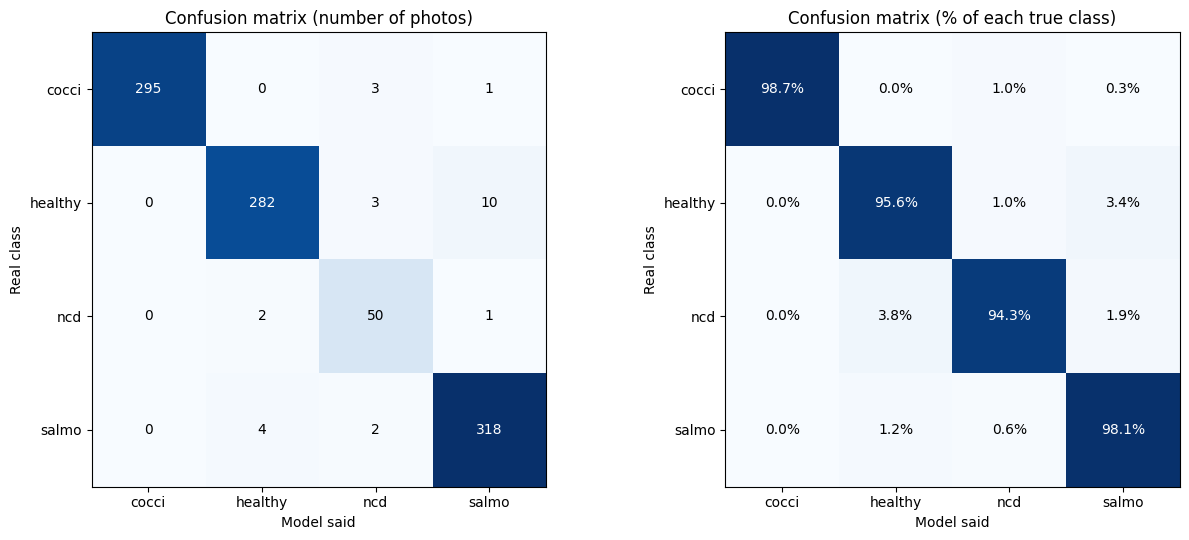

In [16]:
# ===== SECTION D.i | Confusion matrix, per-class accuracy, NCD precision trade-off =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, f1_score

classes = sorted(df.label.unique()); cidx = {c: i for i, c in enumerate(classes)}
va = df[df.split_group == 'val']; te = df[df.split_group == 'test']
y_val, y_te = va.label.map(cidx).values, te.label.map(cidx).values
P_val = np.load('/kaggle/working/probs_improved_val.npy')
P_te  = np.load('/kaggle/working/probs_improved_test.npy')
n = cidx['ncd']

def boost(P, f):
    Q = P.copy(); Q[:, n] *= f
    return Q / Q.sum(1, keepdims=True)

# ---- 1. Trade-off table: NCD boost vs NCD precision / recall ----
print("NCD boost trade-off (VALIDATION = used for choosing, TEST = for information only)")
rows = []
for f in [1, 1.25, 1.5, 2, 3]:
    r = {'boost': f}
    for nm, P, y in [('val', P_val, y_val), ('test', P_te, y_te)]:
        pr = boost(P, f).argmax(1)
        p, rc, f1, _ = precision_recall_fscore_support(y, pr, labels=[n], zero_division=0)
        r[f'{nm}_NCD_prec'] = round(p[0], 3); r[f'{nm}_NCD_recall'] = round(rc[0], 3)
        r[f'{nm}_accuracy'] = round((pr == y).mean(), 3)
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

# ---- 2. Choose boost on VALIDATION: best NCD F1 while NCD recall >= 0.90 ----
best_f, best = 1.5, -1
for f in [1, 1.25, 1.5, 2, 3]:
    pr = boost(P_val, f).argmax(1)
    p, rc, f1, _ = precision_recall_fscore_support(y_val, pr, labels=[n], zero_division=0)
    if rc[0] >= 0.90 and f1[0] > best: best_f, best = f, f1[0]
print("\nBoost chosen on validation:", best_f)

# ---- 3. Final test numbers with that boost ----
pred = boost(P_te, best_f).argmax(1)
cm = confusion_matrix(y_te, pred)

print("\nPER-CLASS RESULTS (test set)")
out = []
for i, c in enumerate(classes):
    tp = cm[i, i]; total = cm[i].sum(); said = cm[:, i].sum()
    tn = cm.sum() - cm[i].sum() - cm[:, i].sum() + tp
    out.append({'class': c, 'found': f'{tp}/{total}',
                'class_accuracy(recall)': round(tp / total, 3),
                'precision': round(tp / said, 3),
                'one_vs_rest_accuracy': round((tp + tn) / cm.sum(), 3)})
print(pd.DataFrame(out).to_string(index=False))
print("Overall accuracy:", round((pred == y_te).mean(), 4),
      "| macro-F1:", round(f1_score(y_te, pred, average='macro'), 4))

# ---- 4. Confusion matrix picture (counts and percentages) ----
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, data, title, fmt in [(ax[0], cm, 'Confusion matrix (number of photos)', 'd'),
                            (ax[1], cm / cm.sum(1, keepdims=True), 'Confusion matrix (% of each true class)', '.1%')]:
    im = a.imshow(data, cmap='Blues')
    a.set_xticks(range(4)); a.set_yticks(range(4))
    a.set_xticklabels(classes); a.set_yticklabels(classes)
    a.set_xlabel('Model said'); a.set_ylabel('Real class'); a.set_title(title)
    for i in range(4):
        for j in range(4):
            a.text(j, i, format(data[i, j], fmt), ha='center', va='center',
                   color='white' if data[i, j] > data.max() / 2 else 'black')
plt.tight_layout(); plt.savefig('/kaggle/working/confusion_matrix.png', dpi=150); plt.show()

                           baseline  improved  change
accuracy                      0.926     0.973   0.047
macro_F1                      0.897     0.959   0.061
sick_caught_%                91.420    99.112   7.692
healthy_wrongly_flagged_%     1.017     4.407   3.390

   class  test_images  recall_base  recall_impr  precision_base  precision_impr  F1_base  F1_impr
  cocci          299        0.987        0.987           0.983           1.000    0.985    0.993
healthy          295        0.990        0.956           0.834           0.979    0.905    0.967
    ncd           53        0.698        0.943           0.902           0.862    0.787    0.901
  salmo          324        0.849        0.981           0.982           0.964    0.911    0.972


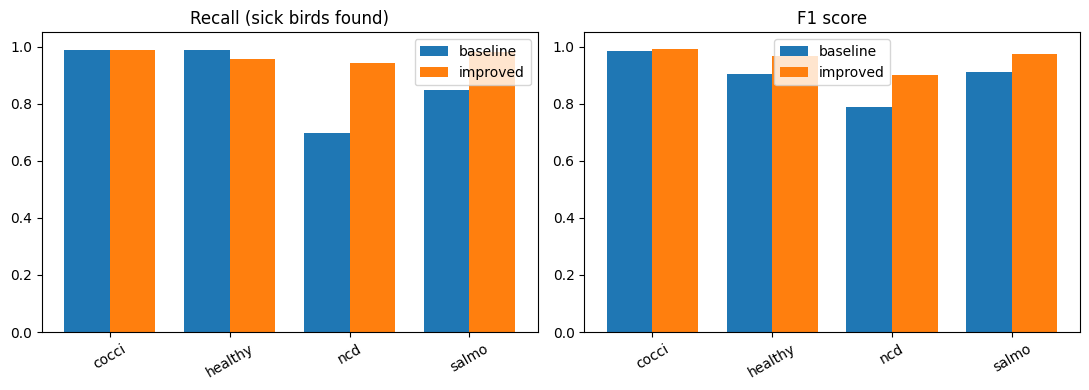

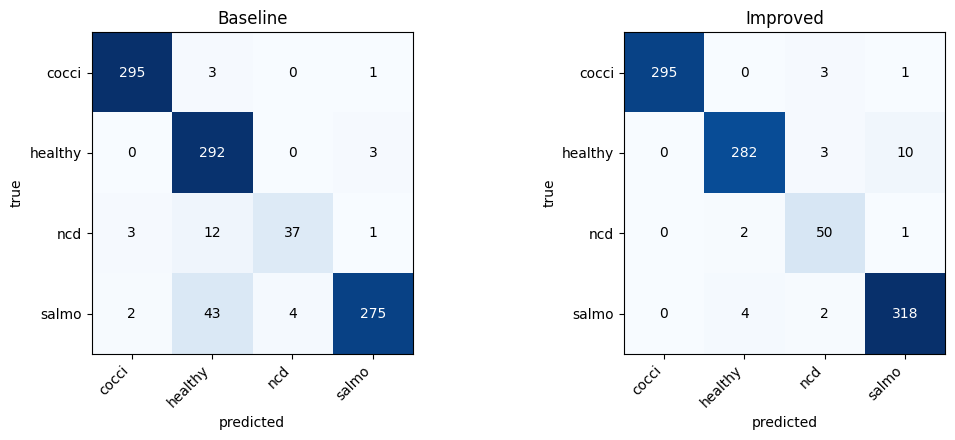


Photos the improved model fixed: 59 | photos it got worse: 13
Test set size: 971 (small differences can be luck, so do not over-claim)

Improved model also adds 'refer to vet': answers 98.5% of photos, 97.9% correct on those; 15 sent to vet (NCD boost 1.5, line 0.6).


In [22]:
# ===== D.iv | Baseline vs improved model (group split, same test set) =====
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_recall_fscore_support

OUT = '/kaggle/working/'
K = len(classes)
P_base = np.load(OUT + 'probs_group.npy')
y = y_te
pb, pi = P_base.argmax(1), pred
assert len(pb) == len(pi) == len(y), "Test sets do not match - rerun both cells on the same df"

def metrics(p):
    h = cidx['healthy']; sick = y != h; flag = p != h
    return {'accuracy': (p == y).mean(), 'macro_F1': f1_score(y, p, average='macro'),
            'sick_caught_%': 100 * (sick & flag).sum() / sick.sum(),
            'healthy_wrongly_flagged_%': 100 * (~sick & flag).sum() / (~sick).sum()}

comp = pd.DataFrame({'baseline': metrics(pb), 'improved': metrics(pi)})
comp['change'] = comp.improved - comp.baseline
print(comp.round(3))

# Per-class table
rb = precision_recall_fscore_support(y, pb, labels=range(K), zero_division=0)
ri = precision_recall_fscore_support(y, pi, labels=range(K), zero_division=0)
pc = pd.DataFrame({'class': classes, 'test_images': rb[3],
                   'recall_base': rb[1], 'recall_impr': ri[1],
                   'precision_base': rb[0], 'precision_impr': ri[0],
                   'F1_base': rb[2], 'F1_impr': ri[2]}).round(3)
print("\n", pc.to_string(index=False))
pc.to_csv(OUT + 'per_class_comparison.csv', index=False)
comp.round(4).to_csv(OUT + 'baseline_vs_improved.csv')

# Chart: per-class recall and F1
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(K); w = 0.38
for a, (b_, i_, t) in zip(ax, [(rb[1], ri[1], 'Recall (sick birds found)'), (rb[2], ri[2], 'F1 score')]):
    a.bar(x - w/2, b_, w, label='baseline'); a.bar(x + w/2, i_, w, label='improved')
    a.set_xticks(x); a.set_xticklabels(classes, rotation=30); a.set_ylim(0, 1.05)
    a.set_title(t); a.legend()
plt.tight_layout(); plt.savefig(OUT + 'fig_compare_bars.png', dpi=150); plt.show()

# Side-by-side confusion matrices
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
draw_cm(ax[0], y, pb, 'Baseline'); draw_cm(ax[1], y, pi, 'Improved')
plt.tight_layout(); plt.savefig(OUT + 'fig_compare_confusion.png', dpi=150); plt.show()

# Which photos changed?
fixed = int(((pb != y) & (pi == y)).sum()); broken = int(((pb == y) & (pi != y)).sum())
print(f"\nPhotos the improved model fixed: {fixed} | photos it got worse: {broken}")
print(f"Test set size: {len(y)} (small differences can be luck, so do not over-claim)")

# Triage (only the improved model has this)
keep = Pt.max(1) >= line
print(f"\nImproved model also adds 'refer to vet': answers {keep.mean()*100:.1f}% of photos, "
      f"{(pi[keep] == y[keep]).mean()*100:.1f}% correct on those; {(~keep).sum()} sent to vet "
      f"(NCD boost {best_f}, line {line}).")

In [25]:
# ===== C.v + Section 3 | README, requirements, and submission zip =====
import os, glob, shutil, tensorflow as tf, sklearn

OUT = '/kaggle/working/'
SUB = OUT + 'submission/'
os.makedirs(SUB, exist_ok=True)

readme = f"""# Capstone Deliverable 2 - Baseline

## What this is
A MobileNetV2 baseline (ImageNet transfer learning) that classifies photos into: {', '.join(classes)}.
It is tested with two splits: a GROUP split (no leakage, main result) and a RANDOM split (to show leakage).

## How to run
1. Upload the dataset to Kaggle and attach it to the notebook. Turn on GPU.
2. Run the notebook cells top to bottom, in this order:
   dataset + quality checks -> splits + leakage check -> environment log ->
   baseline training -> baseline results -> improved model -> comparison -> this cell.
3. Outputs (figures, CSV tables, saved models) appear in /kaggle/working/.

## Settings
Seed 42 | image 224x224 | batch 32 | TensorFlow {tf.__version__} | scikit-learn {sklearn.__version__}
Baseline: dropout 0.3; phase 1 = frozen base, Adam 1e-3, 8 epochs; phase 2 = last 40 layers, Adam 1e-5,
up to 8 epochs with early stopping (patience 3).

## Files
- fig_*.png : charts and sample outputs
- baseline_results.csv, baseline_vs_improved.csv, per_class_comparison.csv, leakage_check.csv : tables
- baseline_group.keras, baseline_random.keras, improved_group.keras : trained models
"""
open(SUB + 'README.md', 'w').write(readme)
open(SUB + 'requirements.txt', 'w').write(f"tensorflow=={tf.__version__}\nscikit-learn=={sklearn.__version__}\nnumpy\npandas\nmatplotlib\npillow\n")

for pat in ['fig_*.png', '*.csv']:
    for f in glob.glob(OUT + pat):
        shutil.copy(f, SUB)
print(shutil.make_archive(OUT + 'deliverable2_submission', 'zip', SUB))

/kaggle/working/deliverable2_submission.zip
